# Gradient descent from scratch: how the learning rate decides convergence

Batch gradient descent for simple linear regression, written with NumPy only, used to study
how the learning rate $\eta$ controls whether the optimiser converges, crawls, or diverges.
The results are checked against the closed-form least-squares solution and against
scikit-learn's `LinearRegression`.

## 1. Problem

We fit a line $\hat{y} = m x + b$ that predicts an exam score from the number of hours studied.
The parameters $(m, b)$ are chosen to minimise the mean squared error

$$L(m, b) = \frac{1}{n} \sum_{i=1}^{n} (m x_i + b - y_i)^2 .$$

This problem has a closed-form solution, which is exactly what makes it a good test bed:
we know the true optimum, so we can measure how close gradient descent gets and how fast,
for each learning rate.

Questions this notebook answers:

1. Which learning rates converge on the raw data, and which diverge?
2. Why is the stable range so narrow, and how does standardising $x$ change it?
3. Do the from-scratch results match the closed form and scikit-learn?

## 2. Data

`data/student_performance.csv` holds two columns from the public Kaggle dataset
[Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors)
(by lainguyn123): `Hours_Studied` and `Exam_Score`. The same rows are embedded in the
interactive explorer `gradient_descent_explorer.html`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path("images").mkdir(exist_ok=True)

df = pd.read_csv("data/student_performance.csv")
x = df["Hours_Studied"].to_numpy(dtype=float)
y = df["Exam_Score"].to_numpy(dtype=float)
n = len(df)

print(f"rows: {n}")
print(df.describe().round(2))
print(f"\nPearson correlation(x, y) = {np.corrcoef(x, y)[0, 1]:.4f}")

rows: 6607
       Hours_Studied  Exam_Score
count        6607.00     6607.00
mean           19.98       67.24
std             5.99        3.89
min             1.00       55.00
25%            16.00       65.00
50%            20.00       67.00
75%            24.00       69.00
max            44.00      101.00

Pearson correlation(x, y) = 0.4455


## 3. Method

### 3.1 Loss, gradient and update rule

With $r_i = m x_i + b - y_i$ the residual of point $i$,

$$\frac{\partial L}{\partial m} = \frac{2}{n}\sum_i x_i r_i, \qquad
\frac{\partial L}{\partial b} = \frac{2}{n}\sum_i r_i .$$

Batch gradient descent repeats, for a learning rate $\eta$,

$$m \leftarrow m - \eta \frac{\partial L}{\partial m}, \qquad
b \leftarrow b - \eta \frac{\partial L}{\partial b}.$$

Every run starts from the same point $(m_0, b_0) = (2, 50)$, the default of the interactive explorer,
and takes a fixed number of iterations. A run is marked **diverged** as soon as the loss is not finite
or exceeds $10^{12}$.

In [2]:
def mse(x, y, m, b):
    r = m * x + b - y
    return np.mean(r * r)

def gradient(x, y, m, b):
    r = m * x + b - y
    return (2.0 / len(x)) * np.sum(x * r), (2.0 / len(x)) * np.sum(r)

def gradient_descent(x, y, lr, n_iter=2000, m0=2.0, b0=50.0, blowup=1e12):
    #Returns the parameter path, the loss history and a diverged flag.
    m, b = m0, b0
    losses = [mse(x, y, m, b)]
    path = [(m, b)]
    diverged = False
    for _ in range(n_iter):
        gm, gb = gradient(x, y, m, b)
        m -= lr * gm
        b -= lr * gb
        L = mse(x, y, m, b)
        losses.append(L)
        path.append((m, b))
        if not np.isfinite(L) or L > blowup:
            diverged = True
            break
    return np.array(path), np.array(losses), diverged

### 3.2 Closed-form optimum

For one feature the least-squares solution is

$$m^\* = \frac{\sum_i (x_i - \bar{x})(y_i - \bar{y})}{\sum_i (x_i - \bar{x})^2}, \qquad
b^\* = \bar{y} - m^\* \bar{x}.$$

This is the target every gradient-descent run should approach.

In [3]:
def ols_closed_form(x, y):
    xm, ym = x.mean(), y.mean()
    m = np.sum((x - xm) * (y - ym)) / np.sum((x - xm) ** 2)
    b = ym - m * xm
    return m, b

m_star, b_star = ols_closed_form(x, y)
L_star = mse(x, y, m_star, b_star)
print(f"closed form: m* = {m_star:.6f}, b* = {b_star:.6f}, MSE* = {L_star:.6f}")

closed form: m* = 0.289291, b* = 61.456984, MSE* = 12.130442


### 3.3 Why there is a maximum stable learning rate

$L$ is quadratic in $(m, b)$, so its Hessian is constant:

$$H = \frac{2}{n}\begin{pmatrix}\sum x_i^2 & \sum x_i\\ \sum x_i & n\end{pmatrix}.$$

Gradient descent on a quadratic converges if and only if $\eta < 2 / \lambda_{\max}(H)$,
where $\lambda_{\max}$ is the largest eigenvalue of $H$. On the raw data $x$ ranges from 1 to 44,
so $\sum x_i^2$ is large, $\lambda_{\max}$ is large and the admissible $\eta$ is tiny.
The ratio $\lambda_{\max}/\lambda_{\min}$ (the condition number) also tells how slowly the
flattest direction converges.

In [4]:
def hessian_eigs(x):
    n = len(x)
    H = (2.0 / n) * np.array([[np.sum(x * x), np.sum(x)], [np.sum(x), n]])
    # 2x2 symmetric eigenvalues in closed form (no linear-algebra library call for the method itself)
    a, d, c = H[0, 0], H[1, 1], H[0, 1]
    tr, det = a + d, a * d - c * c
    disc = np.sqrt(tr * tr / 4 - det)
    return tr / 2 - disc, tr / 2 + disc

lam_min, lam_max = hessian_eigs(x)
eta_max_raw = 2.0 / lam_max
print(f"raw x:   lambda_min = {lam_min:.4f}, lambda_max = {lam_max:.2f}, "
      f"condition number = {lam_max / lam_min:.1f}")
print(f"         stability limit eta < 2/lambda_max = {eta_max_raw:.6f}")

x_std = (x - x.mean()) / x.std()
lam_min_s, lam_max_s = hessian_eigs(x_std)
eta_max_std = 2.0 / lam_max_s
print(f"std. x:  lambda_min = {lam_min_s:.4f}, lambda_max = {lam_max_s:.4f}, "
      f"condition number = {lam_max_s / lam_min_s:.2f}")
print(f"         stability limit eta < 2/lambda_max = {eta_max_std:.4f}")

raw x:   lambda_min = 0.1647, lambda_max = 871.63, condition number = 5293.3
         stability limit eta < 2/lambda_max = 0.002295
std. x:  lambda_min = 2.0000, lambda_max = 2.0000, condition number = 1.00
         stability limit eta < 2/lambda_max = 1.0000


## 4. Results

### 4.1 Learning-rate sweep on the raw data

In [5]:
N_ITER = 2000
LRS_RAW = [1e-5, 1e-4, 5e-4, 1e-3, 2e-3, 5e-3]

runs_raw = {lr: gradient_descent(x, y, lr, N_ITER) for lr in LRS_RAW}

rows = []
for lr, (path, losses, div) in runs_raw.items():
    m_end, b_end = path[-1]
    rows.append({
        "learning rate": lr,
        "iterations run": len(losses) - 1,
        "final MSE": np.nan if div else losses[-1],
        "gap to MSE*": np.nan if div else losses[-1] - L_star,
        "final m": np.nan if div else m_end,
        "final b": np.nan if div else b_end,
        "diverged": div,
    })
sweep_raw = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
sweep_raw

,learning rate,iterations run,final MSE,gap to MSE*,final m,final b,diverged
0,1e-05,2000,22.9916,10.8612,0.81638,49.9836,False
1,0.0001,2000,22.3665,10.236,0.800987,50.3186,False
2,0.0005,2000,19.9955,7.86509,0.737828,51.6934,False
3,0.001,2000,17.7884,5.65795,0.669722,53.1759,False
4,0.002,2000,15.0582,2.92775,0.562952,55.5001,False
5,0.005,9,NaN,NaN,NaN,NaN,True


### 4.2 The same sweep after standardising $x$

With $x$ standardised to zero mean and unit variance, the Hessian becomes $2I$, so every learning
rate below 1 converges and the two parameters converge at the same speed. The fitted line is mapped
back to the original scale afterwards: $m = m_s / \sigma_x$ and $b = b_s - m \bar{x}$.

In [6]:
LRS_STD = [1e-3, 1e-2, 1e-1, 0.5, 0.9, 1.1]
# Start from the point that corresponds to (m, b) = (2, 50) on the raw scale.
m0_s, b0_s = 2.0 * x.std(), 50.0 + 2.0 * x.mean()

runs_std = {lr: gradient_descent(x_std, y, lr, N_ITER, m0=m0_s, b0=b0_s) for lr in LRS_STD}

rows = []
for lr, (path, losses, div) in runs_std.items():
    ms, bs = path[-1]
    m_back, b_back = ms / x.std(), bs - (ms / x.std()) * x.mean()
    rows.append({
        "learning rate": lr,
        "iterations run": len(losses) - 1,
        "final MSE": np.nan if div else losses[-1],
        "gap to MSE*": np.nan if div else losses[-1] - L_star,
        "final m (raw scale)": np.nan if div else m_back,
        "final b (raw scale)": np.nan if div else b_back,
        "diverged": div,
    })
sweep_std = pd.DataFrame(rows)
sweep_std

,learning rate,iterations run,final MSE,gap to MSE*,final m (raw scale),final b (raw scale),diverged
0,0.001,2000,12.3371,0.206654,0.320498,61.248,False
1,0.01,2000,12.1304,1.77636e-15,0.289291,61.457,False
2,0.1,2000,12.1304,1.77636e-15,0.289291,61.457,False
3,0.5,2000,12.1304,0,0.289291,61.457,False
4,0.9,2000,12.1304,0,0.289291,61.457,False
5,1.1,59,NaN,NaN,NaN,NaN,True


### 4.3 How long does the raw data really need?

The raw-data runs above look flat after 2000 iterations but are still far from the optimum.
The slow direction decays by a factor $(1 - \eta\lambda_{\min})$ per step, so its error shrinks by a factor $e$ every $1 / (\eta \lambda_{\min})$ iterations,
and reaching a tight tolerance takes several of those time constants. The cell below runs the best raw
learning rate until the loss is within $10^{-6}$ of the closed-form minimum (capped at 500,000 iterations).

In [7]:
def iterations_to_converge(x, y, lr, tol=1e-6, max_iter=500_000, m0=2.0, b0=50.0):
    m, b = m0, b0
    for k in range(1, max_iter + 1):
        gm, gb = gradient(x, y, m, b)
        m -= lr * gm
        b -= lr * gb
        if mse(x, y, m, b) - L_star < tol:
            return k, m, b
    return None, m, b

best_lr_raw = max(lr for lr, (_, _, div) in runs_raw.items() if not div)
k_raw, m_raw_long, b_raw_long = iterations_to_converge(x, y, best_lr_raw)
print(f"raw x, η = {best_lr_raw:g}: {k_raw} iterations to reach MSE* + 1e-6 "
      f"(time constant 1/(η·λ_min) ≈ {1 / (best_lr_raw * lam_min):,.0f} iterations per e-fold of the slow direction)")
print(f"   m = {m_raw_long:.6f}, b = {b_raw_long:.6f}")

best_lr_std = max(lr for lr, (_, _, div) in runs_std.items() if not div)
k_std, ms, bs = iterations_to_converge(x_std, y, best_lr_std, m0=m0_s, b0=b0_s)
print(f"standardised x, η = {best_lr_std:g}: {k_std} iterations to reach MSE* + 1e-6")

raw x, η = 0.002: 24603 iterations to reach MSE* + 1e-6 (time constant 1/(η·λ_min) ≈ 3,036 iterations per e-fold of the slow direction)
   m = 0.289451, b = 61.453503
standardised x, η = 0.9: 46 iterations to reach MSE* + 1e-6


### 4.4 Loss curves

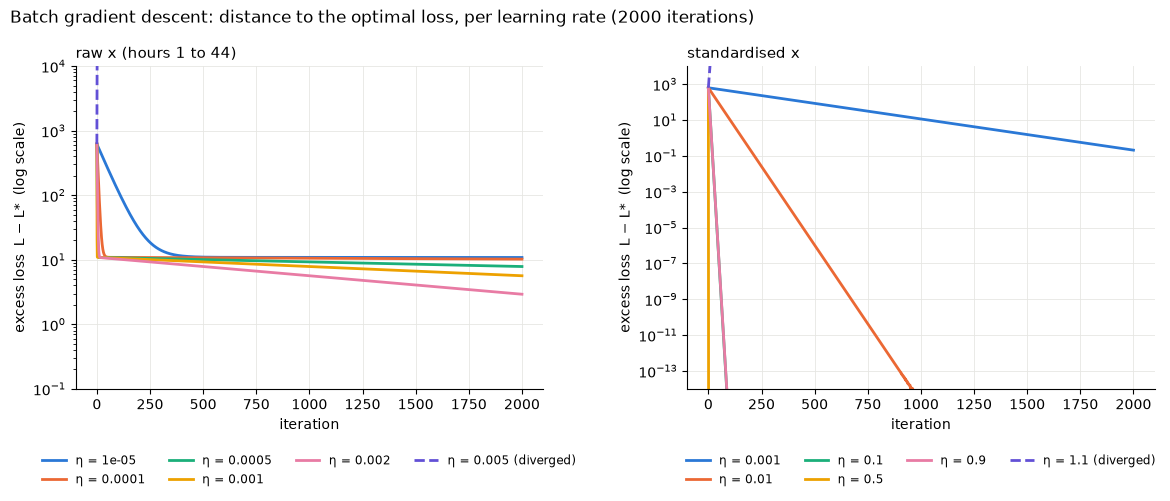

In [8]:
# Fixed categorical order (one hue per learning rate, never cycled); dashed = diverged.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (runs, title) in zip(axes, [(runs_raw, "raw x (hours 1 to 44)"),
                                    (runs_std, "standardised x")]):
    for color, (lr, (path, losses, div)) in zip(PALETTE, runs.items()):
        excess = np.maximum(losses - L_star, 1e-16)
        ax.plot(np.arange(len(excess)), excess, color=color, lw=2,
                ls="--" if div else "-",
                label=f"η = {lr:g}" + (" (diverged)" if div else ""))
    ax.set_yscale("log")
    ax.set_ylim((1e-1, 1e4) if runs is runs_raw else (1e-14, 1e4))
    ax.set_xlabel("iteration")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(True, color="#e6e6e3", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8.5, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17))
for ax in axes: ax.set_ylabel("excess loss  L − L*  (log scale)")
fig.suptitle("Batch gradient descent: distance to the optimal loss, per learning rate (2000 iterations)",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig("images/loss_curves.png", dpi=160, bbox_inches="tight")
plt.show()

### 4.5 Comparison with the closed form and scikit-learn

Three gradient-descent results are compared with the closed-form solution and with
`sklearn.linear_model.LinearRegression`: the raw-data run after 2000 iterations, the raw-data run
continued until convergence, and the standardised run. scikit-learn is used only as a reference;
it plays no part in the fitting above.

In [9]:
from sklearn.linear_model import LinearRegression

path_gd, losses_gd, _ = runs_raw[best_lr_raw]
m_gd, b_gd = path_gd[-1]

ms_end, bs_end = runs_std[best_lr_std][0][-1]
m_gds, b_gds = ms_end / x.std(), bs_end - (ms_end / x.std()) * x.mean()

sk = LinearRegression().fit(x.reshape(-1, 1), y)
m_sk, b_sk = float(sk.coef_[0]), float(sk.intercept_)

compare = pd.DataFrame({
    "method": ["closed form (NumPy)",
               "scikit-learn LinearRegression",
               f"GD, raw x, η={best_lr_raw:g}, {N_ITER} iterations",
               f"GD, raw x, η={best_lr_raw:g}, {k_raw} iterations",
               f"GD, standardised x, η={best_lr_std:g}, {N_ITER} iterations"],
    "slope m": [m_star, m_sk, m_gd, m_raw_long, m_gds],
    "intercept b": [b_star, b_sk, b_gd, b_raw_long, b_gds],
})
compare["MSE"] = [mse(x, y, m, b) for m, b in zip(compare["slope m"], compare["intercept b"])]
compare["R²"] = 1 - compare["MSE"] * n / np.sum((y - y.mean()) ** 2)
compare

,method,slope m,intercept b,MSE,R²
0,closed form (NumPy),0.289291,61.457,12.1304,0.19843
1,scikit-learn LinearRegression,0.289291,61.457,12.1304,0.19843
2,"GD, raw x, η=0.002, 2000 iterations",0.562952,55.5001,15.0582,0.0049666
3,"GD, raw x, η=0.002, 24603 iterations",0.289451,61.4535,12.1304,0.19843
4,"GD, standardised x, η=0.9, 2000 iterations",0.289291,61.457,12.1304,0.19843


In [10]:
print(f"|slope − sklearn|,     GD standardised x: {abs(m_gds - m_sk):.2e}")
print(f"|intercept − sklearn|, GD standardised x: {abs(b_gds - b_sk):.2e}")
print(f"|slope − sklearn|,     GD raw x, {k_raw} it.: {abs(m_raw_long - m_sk):.2e}")
print(f"|intercept − sklearn|, GD raw x, {k_raw} it.: {abs(b_raw_long - b_sk):.2e}")

|slope − sklearn|,     GD standardised x: 8.33e-16
|intercept − sklearn|, GD standardised x: 1.42e-14
|slope − sklearn|,     GD raw x, 24603 it.: 1.60e-04
|intercept − sklearn|, GD raw x, 24603 it.: 3.48e-03


### 4.6 The fitted line

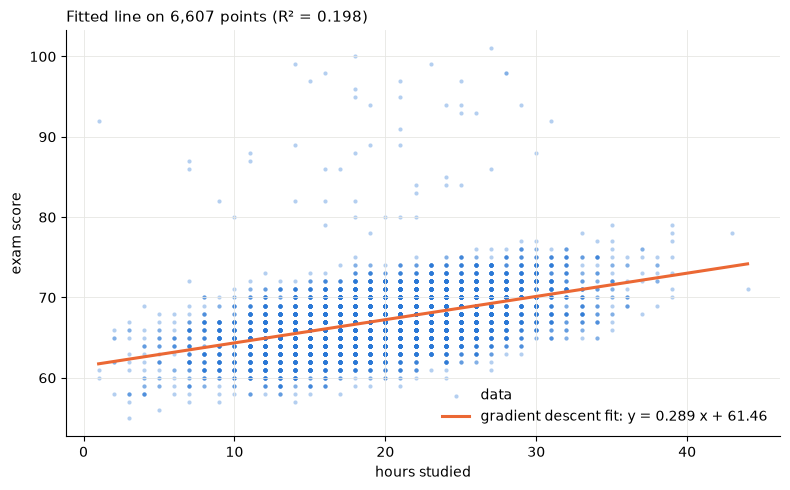

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=9, color="#2a78d6", alpha=0.35, linewidths=0, label="data")
xs = np.array([x.min(), x.max()])
ax.plot(xs, m_gds * xs + b_gds, color="#eb6834", lw=2.2,
        label=f"gradient descent fit: y = {m_gds:.3f} x + {b_gds:.2f}")
ax.set_xlabel("hours studied")
ax.set_ylabel("exam score")
ax.set_title(f"Fitted line on {n:,} points (R² = {compare['R²'].iloc[4]:.3f})", loc="left", fontsize=11)
ax.grid(True, color="#e6e6e3", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("images/fit.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Conclusion

- The stable window on the raw data is set by $\eta < 2/\lambda_{\max}(H)$. The sweep confirms it:
  every learning rate below the bound converges, the first one above it blows up within a few iterations.
- Inside the window, speed is limited by the ill-conditioned intercept direction (condition number in the
  thousands): after 2000 iterations the raw-data runs are still far from the optimum, and the best raw
  learning rate needs tens of thousands of iterations to get there.
- Standardising $x$ makes the Hessian $2I$: every $\eta < 1$ converges, and $\eta$ near 1 reaches the optimum
  in a handful of steps. Feature scaling decides both the admissible learning rate and the speed.
- Once converged, gradient descent matches the closed form and scikit-learn to machine precision,
  which validates the implementation.